# CMPSC 448 midterm project - Sungmin Song

Data comes from the public AlpacaEval dataset (805 instructions × 4 LLMs)
        
To run,

Select Runtime → Change runtime type → T4 GPU

Select Runtime → Run all

## 1. Mount Drive and enter the project folder

In [ ]:
import os, torch
os.makedirs('/content/llm-fingerprint', exist_ok=True)
%cd /content/llm-fingerprint
print('GPU available:', torch.cuda.is_available())

/content/llm-fingerprint
GPU available: True


## 2. Write the code files

In [ ]:
%%writefile get_public_data.py
"""Builds data/responses.jsonl from a PUBLIC dataset instead of calling APIs.

Source: AlpacaEval (Li et al., 2023; github.com/tatsu-lab/alpaca_eval).
  - 805 fixed instructions; the repo publishes each model's answer to all 805
    in results/<model>/model_outputs.json.
  - Data license: CC BY-NC 4.0

Run:  python get_public_data.py      (needs internet access to GitHub)
"""
import json, os, re, urllib.request

REPO = "https://raw.githubusercontent.com/tatsu-lab/alpaca_eval/main/results/{}/model_outputs.json"
MODELS = {  # label: (family, AlpacaEval folder name)
    "gpt":      ("GPT (OpenAI)",       "gpt-4o-2024-05-13"),
    "claude":   ("Claude (Anthropic)", "claude-3-5-sonnet-20240620"),
    "llama":    ("Llama (Meta)",       "Meta-Llama-3.1-70B-Instruct-Turbo"),
    "gemini":   ("Gemini (Google)",    "gemini-pro"),
    # "qwen":     ("Qwen (Alibaba)",     "Qwen2-72B-Instruct"),
    # "mistral":  ("Mistral",            "mistral-large-2402"),
    # "deepseek": ("DeepSeek",           "deepseek-llm-67b-chat"),
}

# AlpacaEval has no task labels, so we assign one with transparent keyword rules
# (order matters: first match wins). Used for RQ3. Spot-check some by hand and
# report that the labels are heuristic. Coding and math are merged into
# "technical" because math alone has only ~38 instructions.
TASK_RULES = [
    ("technical", r"\b(code|python|javascript|java|c\+\+|function|sql|program|script|html|css|regex|algorithm|bug|compile)\b"),
    # math: explicit math words only. Digit patterns ("70-75 dB", "9-11 am") and
    # "how many"/"solve" (trivia, crosswords) were checked by hand and mislabel too much.
    ("technical", r"\b(calculate|equation|math|mathematical|probability|integral|derivative|sum of|f\(x\))"),
    ("writing", r"\b(write|poem|story|essay|letter|email|slogan|tweet|song|lyrics|haiku|blog|rewrite|paraphrase|caption)\b"),
]

def task_of(text):
    t = text.lower()
    for name, pat in TASK_RULES:
        if re.search(pat, t):
            return name
    return "general_qa"

def fetch(folder):
    with urllib.request.urlopen(REPO.format(folder), timeout=60) as r:
        return json.load(r)

if __name__ == "__main__":
    os.makedirs("data", exist_ok=True)
    data = {}
    for llm, (family, folder) in MODELS.items():
        rows = fetch(folder)
        # match by instruction TEXT, not position (some files are in a different order)
        data[llm] = {r["instruction"]: r for r in rows}
        print(f"{llm:9s} {folder:36s} {len(rows)} rows")
    common = sorted(set.intersection(*(set(d) for d in data.values())))
    ids = {instr: i for i, instr in enumerate(common)}
    n = 0
    with open("data/responses.jsonl", "w", encoding="utf-8") as f:
        for llm, (family, folder) in MODELS.items():
            for instr in common:
                r = data[llm][instr]
                rec = dict(llm=llm, family=family, model_id=folder, prompt_id=ids[instr],
                           task=task_of(instr), source=r.get("dataset"), input=instr,
                           output=(r.get("output") or "").strip(), finish_reason="unknown")
                f.write(json.dumps(rec, ensure_ascii=False) + "\n"); n += 1
    print(f"\n{len(common)} shared instructions x {len(MODELS)} models = {n} rows -> data/responses.jsonl")
    from collections import Counter
    print("task labels (per instruction):", dict(Counter(task_of(i) for i in common)))


Overwriting get_public_data.py


In [ ]:
%%writefile train.py
"""CNN and BiLSTM classifiers for identifying which LLM wrote a response.

Experiments (each writes results/<name>.json and prints a summary table):
  RQ1  output-only classification (CNN, BiLSTM, + TF-IDF/LogReg baseline)
  RQ2  input-only vs output-only vs input+output
  RQ3  held-out task group: same-size training with vs without that task, same test set
  RQ4  style statistics, feature-only classifier, and signal-removal ablations

Run (Colab, GPU runtime):
  python train.py --rq 1 2 3 4          # everything (~10-20 min on a T4)
  python train.py --rq 1 --seeds 1      # quick check

Design choices worth explaining in the report:
  * Split is BY PROMPT: a prompt and all of its responses land in exactly one of
    train/val/test, so the test set has only unseen prompts.
  * Every prompt was answered by every model, so classes are perfectly balanced
    and the input alone carries no label information (chance = 1/num_models).
  * Tokenizer keeps case, punctuation, and newlines as tokens, because
    formatting (markdown, bullets, line breaks) is plausibly part of the fingerprint.
  * Each run is repeated over several seeds; we report mean +/- std.
"""
import argparse, json, os, random, re, time
from collections import Counter

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PAD, UNK, SEP = 0, 1, 2
MAX_IN, MAX_OUT = 64, 600

# ----------------------------------------------------------------------------- data

def load_data(path):
    rows = [json.loads(l) for l in open(path, encoding="utf-8")]
    df = pd.DataFrame(rows)
    df["output"] = df["output"].fillna("").astype(str)
    df = df[df["output"].str.strip() != ""]                     # empty responses are unusable
    df = df.drop_duplicates(["llm", "prompt_id"])
    # keep only prompts answered by every model -> perfectly balanced classes
    n_models = df["llm"].nunique()
    full = df.groupby("prompt_id")["llm"].nunique()
    df = df[df["prompt_id"].isin(full[full == n_models].index)].reset_index(drop=True)
    return df

def split_by_prompt(df, seed, test=0.15, val=0.15):
    p = df.drop_duplicates("prompt_id")[["prompt_id", "task"]]
    tr, te = train_test_split(p, test_size=test, stratify=p["task"], random_state=seed)
    tr, va = train_test_split(tr, test_size=val / (1 - test), stratify=tr["task"], random_state=seed)
    pick = lambda s: df[df["prompt_id"].isin(s["prompt_id"])].reset_index(drop=True)
    return pick(tr), pick(va), pick(te)

def split_train_val(df, seed, val=0.15):
    p = df.drop_duplicates("prompt_id")[["prompt_id", "task"]]
    tr, va = train_test_split(p, test_size=val, stratify=p["task"], random_state=seed)
    pick = lambda s: df[df["prompt_id"].isin(s["prompt_id"])].reset_index(drop=True)
    return pick(tr), pick(va)

TOKEN_RE = re.compile(r"\n|\w+|[^\w\s]")

def tokenize(text):
    return TOKEN_RE.findall(text)

# Signal-removal transforms used by the RQ4 ablations
def strip_formatting(t):
    t = re.sub(r"```.*?\n", "", t)                 # code fence lines' language tags
    t = re.sub(r"[#*_`>|~]", " ", t)                # markdown symbols
    t = re.sub(r"^\s*([-+]|\d+\.)\s+", " ", t, flags=re.M)  # list markers
    return re.sub(r"\s+", " ", t).strip()           # collapse all whitespace/newlines

def lower_no_punct(t):
    return re.sub(r"\s+", " ", re.sub(r"[^\w\s]", " ", t.lower())).strip()

TRANSFORMS = {"none": lambda t: t, "no_format": strip_formatting, "lower_no_punct": lower_no_punct}

class Vocab:
    def __init__(self, token_lists, min_freq=2, max_size=30000):
        c = Counter(t for toks in token_lists for t in toks)
        self.itos = ["<pad>", "<unk>", "<sep>"] + [t for t, n in c.most_common(max_size)
                                                   if n >= min_freq and t not in ("<pad>", "<unk>", "<sep>")]
        self.stoi = {t: i for i, t in enumerate(self.itos)}
    def encode(self, toks):
        return [self.stoi.get(t, UNK) for t in toks]
    def __len__(self):
        return len(self.itos)

def make_sequences(df, mode, transform, max_out):
    seqs = []
    for inp, out in zip(df["input"], df["output"]):
        ti, to = tokenize(inp)[:MAX_IN], tokenize(TRANSFORMS[transform](out))[:max_out]
        if mode == "input":
            s = ti
        elif mode == "output":
            s = to
        else:  # both
            s = ti + ["<sep>"] + to
        seqs.append(s if s else ["<unk>"])
    return seqs

def to_tensor(seqs, vocab):
    ids = [vocab.encode(s) for s in seqs]
    L = max(len(x) for x in ids)
    X = torch.full((len(ids), L), PAD, dtype=torch.long)
    for i, x in enumerate(ids):
        X[i, :len(x)] = torch.tensor(x)
    return X, torch.tensor([len(x) for x in ids])

# ----------------------------------------------------------------------------- models

class CNN(nn.Module):
    """Kim (2014)-style text CNN: parallel 1D convolutions with widths 3/4/5
    act as learned n-gram detectors; max-over-time pooling keeps each
    filter's strongest match anywhere in the text."""
    def __init__(self, vocab_size, n_classes, emb=128, filters=128, widths=(3, 4, 5), dropout=0.5):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.convs = nn.ModuleList([nn.Conv1d(emb, filters, w, padding=w // 2) for w in widths])
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(filters * len(widths), n_classes)
    def forward(self, x, lengths):
        e = self.emb(x).transpose(1, 2)                         # B x E x T
        mask = (x != PAD).unsqueeze(1)                          # B x 1 x T
        pooled = []
        for conv in self.convs:
            h = torch.relu(conv(e))[:, :, :x.size(1)]
            h = h.masked_fill(~mask, -1e4)                      # ignore padding in the max
            pooled.append(h.max(dim=2).values)
        return self.fc(self.drop(torch.cat(pooled, 1)))

class BiLSTM(nn.Module):
    """Bidirectional LSTM over the token sequence. The text is represented by
    the final hidden states of both directions concatenated with a max-pool
    over all time steps (the max-pool helps on long responses, where the final
    state alone forgets early content)."""
    def __init__(self, vocab_size, n_classes, emb=128, hidden=128, dropout=0.5):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.lstm = nn.LSTM(emb, hidden, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(4 * hidden, n_classes)
    def forward(self, x, lengths):
        e = self.drop(self.emb(x))
        packed = nn.utils.rnn.pack_padded_sequence(e, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, (h, _) = self.lstm(packed)
        out, _ = nn.utils.rnn.pad_packed_sequence(out, batch_first=True, padding_value=-1e4)
        last = torch.cat([h[0], h[1]], dim=1)                   # forward + backward final states
        mx = out.max(dim=1).values
        return self.fc(self.drop(torch.cat([last, mx], 1)))

# ----------------------------------------------------------------------------- training

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def batches(X, L, y, bs, shuffle):
    idx = torch.randperm(len(y)) if shuffle else torch.arange(len(y))
    for i in range(0, len(y), bs):
        j = idx[i:i + bs]
        m = int(L[j].max())
        yield X[j, :m].to(DEVICE), L[j], y[j].to(DEVICE)

@torch.no_grad()
def predict(model, X, L, bs=64):
    model.eval()
    preds = []
    for xb, lb, _ in batches(X, L, torch.zeros(len(L), dtype=torch.long), bs, False):
        preds.append(model(xb, lb).argmax(1).cpu())
    return torch.cat(preds).numpy()

def train_nn(arch, train, val, labels, mode="output", transform="none", max_out=MAX_OUT,
             seed=0, epochs=15, bs=32, lr=1e-3, patience=4):
    set_seed(seed)
    tr_seq = make_sequences(train, mode, transform, max_out)
    vocab = Vocab(tr_seq)                                       # vocab from TRAIN only
    lab = {l: i for i, l in enumerate(labels)}
    Xtr, Ltr = to_tensor(tr_seq, vocab); ytr = torch.tensor(train["llm"].map(lab).values)
    Xva, Lva = to_tensor(make_sequences(val, mode, transform, max_out), vocab); yva = val["llm"].map(lab).values
    model = (CNN if arch == "cnn" else BiLSTM)(len(vocab), len(labels)).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    lossf = nn.CrossEntropyLoss()
    best, best_state, bad, hist = -1, None, 0, []
    for ep in range(epochs):
        model.train(); tot = 0
        for xb, lb, yb in batches(Xtr, Ltr, ytr, bs, True):
            opt.zero_grad()
            loss = lossf(model(xb, lb), yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step(); tot += loss.item() * len(yb)
        vf1 = f1_score(yva, predict(model, Xva, Lva), average="macro")
        hist.append(dict(epoch=ep + 1, train_loss=tot / len(ytr), val_macro_f1=vf1))
        if vf1 > best:
            best, bad = vf1, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break                          # early stopping on val macro-F1
    model.load_state_dict(best_state)
    def evaluate(df):
        X, L = to_tensor(make_sequences(df, mode, transform, max_out), vocab)
        return np.array(labels)[predict(model, X, L)]       # back to label strings
    return evaluate, hist

def tfidf_baseline(train, labels, mode="output", transform="none"):
    """Linear baseline: word 1-2gram + char 2-4gram TF-IDF -> logistic regression."""
    def texts(df):
        t = df["output"].map(TRANSFORMS[transform])
        if mode == "input": return df["input"]
        if mode == "both": return df["input"] + " <sep> " + t
        return t
    vec_w = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000, sublinear_tf=True, lowercase=False, token_pattern=r"(?u)\b\w+\b|[^\w\s]")
    vec_c = TfidfVectorizer(analyzer="char", ngram_range=(2, 4), min_df=2, max_features=50000, sublinear_tf=True)
    from scipy.sparse import hstack
    Xtr = hstack([vec_w.fit_transform(texts(train)), vec_c.fit_transform(texts(train))])
    clf = LogisticRegression(max_iter=2000, C=10).fit(Xtr, train["llm"])
    return lambda df: clf.predict(hstack([vec_w.transform(texts(df)), vec_c.transform(texts(df))]))

def metrics(y_true, y_pred, labels):
    return dict(acc=accuracy_score(y_true, y_pred), macro_f1=f1_score(y_true, y_pred, average="macro"),
                cm=confusion_matrix(y_true, y_pred, labels=labels).tolist())

def summarize(runs):
    """runs: list of metric dicts over seeds -> mean/std (+ summed confusion matrix)."""
    out = {}
    for k in ("acc", "macro_f1"):
        v = [r[k] for r in runs]
        out[k] = float(np.mean(v)); out[k + "_std"] = float(np.std(v))
    out["cm"] = np.sum([r["cm"] for r in runs], axis=0).tolist()
    return out

def run_setting(df, labels, seeds, epochs, arches=("cnn", "lstm", "tfidf"), **kw):
    """Train/eval each architecture over seeds on by-prompt splits. Also returns
    per-task accuracy so RQ3 can compare in-domain vs cross-domain."""
    res = {}
    for arch in arches:
        runs, per_task, hists = [], [], []
        for s in seeds:
            tr, va, te = split_by_prompt(df, s)
            if arch == "tfidf":
                ev = tfidf_baseline(tr, labels, kw.get("mode", "output"), kw.get("transform", "none"))
            else:
                ev, h = train_nn(arch, tr, va, labels, seed=s, epochs=epochs, **kw); hists.append(h)
            pred = ev(te)
            runs.append(metrics(te["llm"].values, pred, labels))
            per_task.append({t: accuracy_score(te["llm"][te["task"] == t], pred[(te["task"] == t).values])
                             for t in sorted(te["task"].unique())})
        res[arch] = summarize(runs)
        res[arch]["per_task_acc"] = {t: float(np.mean([p[t] for p in per_task])) for t in per_task[0]}
        if hists: res[arch]["history_seed0"] = hists[0]
        print(f"    {arch:6s} acc={res[arch]['acc']:.3f}±{res[arch]['acc_std']:.3f}  "
              f"macroF1={res[arch]['macro_f1']:.3f}±{res[arch]['macro_f1_std']:.3f}")
    return res

# ----------------------------------------------------------------------------- RQ4 style features

def style_features(text):
    words = re.findall(r"\b\w+\b", text)
    lines = text.split("\n")
    low = [w.lower() for w in words]
    win = low[:200]                                             # TTR on a fixed window so it's not just a length effect
    return dict(
        n_chars=len(text), n_words=len(words),
        avg_word_len=np.mean([len(w) for w in words]) if words else 0,
        ttr_first200=len(set(win)) / len(win) if win else 0,
        n_lines=len(lines), blank_line_frac=sum(1 for l in lines if not l.strip()) / max(1, len(lines)),
        headers=len(re.findall(r"^\s*#{1,6}\s", text, re.M)),
        bullets=len(re.findall(r"^\s*[-*+]\s", text, re.M)),
        numbered=len(re.findall(r"^\s*\d+\.\s", text, re.M)),
        bold=len(re.findall(r"\*\*[^*]+\*\*", text)),
        code_blocks=text.count("```") // 2,
        latex=len(re.findall(r"\\\(|\\\[|\$\$|\\frac|\\boxed", text)),
        emoji=len(re.findall(r"[\U0001F300-\U0001FAFF☀-➿]", text)),
        questions=text.count("?"), exclaims=text.count("!"),
        avg_sent_len=len(words) / max(1, len(re.findall(r"[.!?](\s|$)", text))),
    )

SELF_NAMES = r"\b(?:openai|chatgpt|gpt-?\d|gemini|google|bard|llama|meta ai|deepseek|anthropic|claude|qwen|mistral)\b"

def self_mentions(df):
    """Fraction of each model's outputs that name an LLM/company. If high, the
    classifier could 'cheat' on these tokens; report it, and RQ4 masks them."""
    hit = df["output"].str.lower().str.contains(SELF_NAMES, regex=True)
    return hit.groupby(df["llm"]).mean().round(3).to_dict()

def mask_names(t):
    return re.sub(SELF_NAMES, "<model>", t, flags=re.I)

TRANSFORMS["mask_names"] = mask_names

def top_ngrams(df, k=15):
    """Most indicative word 1-2grams per model (positive LogReg weights on TF-IDF).
    Descriptive only (fit on all data), answers RQ4 'what signals are used?'."""
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True, lowercase=False,
                          token_pattern=r"(?u)\b\w+\b|[^\w\s]")
    X = vec.fit_transform(df["output"])
    clf = LogisticRegression(max_iter=3000, C=10).fit(X, df["llm"])
    vocab = np.array(vec.get_feature_names_out())
    W = clf.coef_ if len(clf.classes_) > 2 else np.vstack([-clf.coef_[0], clf.coef_[0]])
    return {c: [repr(x)[1:-1] for x in vocab[np.argsort(-W[i])[:k]]] for i, c in enumerate(clf.classes_)}

# ----------------------------------------------------------------------------- main

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data", default="data/responses.jsonl")
    ap.add_argument("--rq", nargs="+", type=int, default=[1, 2])
    ap.add_argument("--seeds", type=int, default=3)
    ap.add_argument("--epochs", type=int, default=15)
    ap.add_argument("--out", default="results")
    ap.add_argument("--archs", nargs="+", default=["cnn", "lstm", "tfidf"], help="subset of: cnn lstm tfidf")
    args = ap.parse_args()
    os.makedirs(args.out, exist_ok=True)
    seeds = list(range(args.seeds))
    archs = tuple(args.archs)

    df = load_data(args.data)
    labels = sorted(df["llm"].unique())
    info = dict(n_samples=len(df), n_prompts=df["prompt_id"].nunique(), labels=labels,
                per_class=df["llm"].value_counts().to_dict(), per_task=df.drop_duplicates("prompt_id")["task"].value_counts().to_dict(),
                truncated_frac=(df["finish_reason"] == "length").groupby(df["llm"]).mean().round(3).to_dict() if "finish_reason" in df else None,
                self_mention_frac=self_mentions(df), device=str(DEVICE))
    print(json.dumps(info, indent=1))
    json.dump(info, open(f"{args.out}/dataset_info.json", "w"), indent=1)
    save = lambda name, obj: json.dump(obj, open(f"{args.out}/{name}.json", "w"), indent=1)

    if 1 in args.rq or 2 in args.rq:
        modes = ["output"] if 2 not in args.rq else ["input", "output", "both"]
        res = {}
        for m in modes:
            print(f"\n== mode: {m}")
            res[m] = run_setting(df, labels, seeds, args.epochs, arches=archs, mode=m)
        save("rq1_rq2", dict(labels=labels, chance=1 / len(labels), results=res))

    if 3 in args.rq:
        sizes = df.drop_duplicates("prompt_id")["task"].value_counts()
        held_groups = [g for g in sizes.index if g != sizes.idxmax()]
        n_train = int(0.85 * (sizes.sum() - max(sizes[g] for g in held_groups))) - 1
        print(f"\n== RQ3: held-out groups {held_groups}; training size fixed at {n_train} prompts")
        res = {}
        for held in held_groups:
            res[held] = {}
            for arch in archs:
                seen_runs, unseen_runs = [], []
                for s in seeds:
                    rng = np.random.RandomState(s)
                    G = df[df["task"] == held]; O = df[df["task"] != held]
                    gp = G["prompt_id"].unique(); rng.shuffle(gp)
                    g_test, g_pool = gp[:len(gp) // 2], gp[len(gp) // 2:]
                    o_tr, o_va = split_train_val(O, s)
                    o_ids = o_tr["prompt_id"].unique(); rng.shuffle(o_ids)
                    pick = lambda ids: df[df["prompt_id"].isin(ids)].reset_index(drop=True)
                    unseen_tr = pick(o_ids[:n_train])
                    seen_tr = pick(np.concatenate([g_pool, o_ids[:n_train - len(g_pool)]]))
                    test = pick(g_test)
                    for tr, runs in ((unseen_tr, unseen_runs), (seen_tr, seen_runs)):
                        ev = tfidf_baseline(tr, labels) if arch == "tfidf" else train_nn(arch, tr, o_va, labels, seed=s, epochs=args.epochs)[0]
                        runs.append(metrics(test["llm"].values, ev(test), labels))
                res[held][arch] = dict(seen=summarize(seen_runs), unseen=summarize(unseen_runs),
                                       n_train_prompts=n_train, n_test_prompts=len(g_test))
                print(f"    {held:10s} {arch:6s} seen={res[held][arch]['seen']['acc']:.3f}  unseen={res[held][arch]['unseen']['acc']:.3f}"
                      f"  (test prompts={len(g_test)})")
        save("rq3", dict(labels=labels, chance=1 / len(labels), results=res))

    if 4 in args.rq:
        # (a) descriptive statistics per model
        feats = pd.DataFrame([style_features(t) for t in df["output"]])
        feats["llm"], feats["task"] = df["llm"].values, df["task"].values
        stats = feats.groupby("llm").mean(numeric_only=True).round(3)
        stats_task = feats.groupby(["task", "llm"]).mean(numeric_only=True).round(2)
        print("\n== RQ4 style statistics (mean per model)\n", stats.T.to_string())
        stats.to_csv(f"{args.out}/rq4_style_stats.csv"); stats_task.to_csv(f"{args.out}/rq4_style_stats_by_task.csv")
        # (b) how far do style features alone get? (logistic regression, same splits)
        fcols = [c for c in feats.columns if c not in ("llm", "task")]
        runs, coefs = [], []
        for s in seeds:
            tr, _, te = split_by_prompt(df, s)
            Xtr = feats.loc[df["prompt_id"].isin(tr["prompt_id"]), fcols]; ytr = feats.loc[Xtr.index, "llm"]
            Xte = feats.loc[df["prompt_id"].isin(te["prompt_id"]), fcols]; yte = feats.loc[Xte.index, "llm"]
            sc = StandardScaler().fit(Xtr)
            clf = LogisticRegression(max_iter=3000).fit(sc.transform(Xtr), ytr)
            runs.append(metrics(yte.values, clf.predict(sc.transform(Xte)), labels)); coefs.append(clf.coef_)
        feat_only = summarize(runs)
        coef = pd.DataFrame(np.mean(coefs, 0), index=clf.classes_, columns=fcols).round(2)
        coef.to_csv(f"{args.out}/rq4_feature_coefs.csv")
        print(f"\n    style-features-only LogReg acc={feat_only['acc']:.3f}±{feat_only['acc_std']:.3f}")
        top = top_ngrams(df)
        print("\n== RQ4 most indicative n-grams per model")
        for c, ws in top.items(): print(f"    {c:10s}", " | ".join(ws))
        # (c) ablations: remove a signal, retrain, measure the drop
        ablations = {
            "full": dict(transform="none", max_out=MAX_OUT),
            "mask_model_names": dict(transform="mask_names", max_out=MAX_OUT),  # self-identification removed
            "no_format": dict(transform="no_format", max_out=MAX_OUT),         # markdown + line breaks removed
            "lower_no_punct": dict(transform="lower_no_punct", max_out=MAX_OUT),  # only lowercased words remain
            "first_50_tokens": dict(transform="none", max_out=50),              # removes most length/structure info
        }
        abl = {}
        for name, kw in ablations.items():
            print(f"\n== RQ4 ablation: {name}")
            abl[name] = run_setting(df, labels, seeds, args.epochs, arches=tuple(a for a in archs if a != "tfidf"), mode="output", **kw)
        save("rq4", dict(labels=labels, feature_only=feat_only, top_ngrams=top, ablations=abl, style_stats=stats.to_dict()))

    print(f"\nresults written to {args.out}/ ; run `python report_figs.py` for figures/tables")

if __name__ == "__main__":
    t = time.time(); main(); print(f"total time {time.time() - t:.0f}s")


Overwriting train.py


In [ ]:
%%writefile report_figs.py
"""Turns results/*.json into figures (results/figs/*.png) and results/tables.md
for the report. Run after train.py:  python report_figs.py
"""
import json, os
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

R, F = "results", "results/figs"
os.makedirs(F, exist_ok=True)
load = lambda n: json.load(open(f"{R}/{n}.json")) if os.path.exists(f"{R}/{n}.json") else None
NAMES = {"cnn": "CNN", "lstm": "BiLSTM", "tfidf": "TF-IDF + LogReg"}
md = []

def bars(ax, groups, series, values, errs, ylabel, chance=None):
    x = np.arange(len(groups)); w = 0.8 / len(series)
    for i, s in enumerate(series):
        ax.bar(x + (i - (len(series) - 1) / 2) * w, values[i], w, yerr=errs[i], capsize=3, label=s)
    ax.set_xticks(x); ax.set_xticklabels(groups); ax.set_ylabel(ylabel); ax.set_ylim(0, 1.25); ax.set_yticks(np.arange(0, 1.01, 0.2))
    if chance is not None:
        ax.axhline(chance, ls="--", c="gray", lw=1); ax.text(len(groups) - 0.5, chance + 0.02, "chance", color="gray", ha="right")
    ax.legend(frameon=False, loc="upper left", ncol=len(series), fontsize=8); ax.spines[["top", "right"]].set_visible(False)

def cm_plot(cm, labels, title, path):
    cm = np.array(cm, dtype=float); cmn = cm / cm.sum(1, keepdims=True)
    fig, ax = plt.subplots(figsize=(4.2, 3.8))
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", color="white" if cmn[i, j] > 0.5 else "black", fontsize=9)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=30)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title, fontsize=10)
    fig.tight_layout(); fig.savefig(path, dpi=200); plt.close(fig)

r12 = load("rq1_rq2")
if r12:
    labels, res, chance = r12["labels"], r12["results"], r12["chance"]
    md += ["## RQ1/RQ2: accuracy and macro-F1 (mean ± std over seeds, test = unseen prompts)\n",
           f"Chance = {chance:.3f}\n", "| Input | Model | Accuracy | Macro-F1 |", "|---|---|---|---|"]
    for mode, rr in res.items():
        for a, m in rr.items():
            md.append(f"| {mode} | {NAMES[a]} | {m['acc']:.3f} ± {m['acc_std']:.3f} | {m['macro_f1']:.3f} ± {m['macro_f1_std']:.3f} |")
    for a in [x for x in ("cnn", "lstm") if x in res["output"]]:
        cm_plot(res["output"][a]["cm"], labels, f"RQ1 {NAMES[a]} (output only)", f"{F}/rq1_cm_{a}.png")
    modes = list(res); archs = list(res[modes[0]])
    fig, ax = plt.subplots(figsize=(6, 3.5))
    bars(ax, modes, [NAMES[a] for a in archs], [[res[m][a]["acc"] for m in modes] for a in archs],
         [[res[m][a]["acc_std"] for m in modes] for a in archs], "Test accuracy", chance)
    ax.set_title("RQ2: what the classifier sees"); fig.tight_layout(); fig.savefig(f"{F}/rq2_modes.png", dpi=200); plt.close(fig)
    # training curves (seed 0, output only)
    nn = [x for x in ("cnn", "lstm") if x in res["output"]]
    if nn:
        fig, axs = plt.subplots(1, 2, figsize=(8, 3))
        for a in nn:
            h = res["output"][a].get("history_seed0", [])
            axs[0].plot([e["epoch"] for e in h], [e["train_loss"] for e in h], marker="o", label=NAMES[a])
            axs[1].plot([e["epoch"] for e in h], [e["val_macro_f1"] for e in h], marker="o", label=NAMES[a])
        axs[0].set_title("Train loss"); axs[1].set_title("Validation macro-F1")
        for ax in axs: ax.set_xlabel("Epoch"); ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
        fig.tight_layout(); fig.savefig(f"{F}/training_curves.png", dpi=200); plt.close(fig)
    first = next(iter(res["output"].values()))["per_task_acc"]
    md += ["\n### Per-task test accuracy (output only)\n", "| Model | " + " | ".join(first) + " |",
           "|---|" + "---|" * len(first)]
    for a, m in res["output"].items():
        md.append(f"| {NAMES[a]} | " + " | ".join(f"{v:.3f}" for v in m["per_task_acc"].values()) + " |")

r3 = load("rq3")
if r3:
    groups = list(r3["results"]); archs = [a for a in ("cnn", "lstm", "tfidf") if a in r3["results"][groups[0]]]
    any_ = r3["results"][groups[0]][archs[0]]
    md += ["\n## RQ3: does the classifier work on a task type it never saw?\n",
           f"Same training size ({any_['n_train_prompts']} prompts) in both conditions; both tested on the same held-out prompts of the task.\n",
           "| Held-out task | Model | Seen task | Unseen task | Drop |", "|---|---|---|---|---|"]
    fig, axs = plt.subplots(1, len(archs), figsize=(4 * len(archs), 3.3), sharey=True, squeeze=False)
    for ax, a in zip(axs[0], archs):
        seen = [r3["results"][g][a]["seen"]["acc"] for g in groups]
        unseen = [r3["results"][g][a]["unseen"]["acc"] for g in groups]
        for g, s_, u in zip(groups, seen, unseen):
            sd = r3["results"][g][a]
            md.append(f"| {g} (n={sd['n_test_prompts']}) | {NAMES[a]} | {s_:.3f} ± {sd['seen']['acc_std']:.3f} | {u:.3f} ± {sd['unseen']['acc_std']:.3f} | {s_ - u:+.3f} |")
        bars(ax, groups, ["seen task", "unseen task"], [seen, unseen],
             [[r3["results"][g][a]["seen"]["acc_std"] for g in groups], [r3["results"][g][a]["unseen"]["acc_std"] for g in groups]],
             "Accuracy", r3["chance"])
        ax.set_title(NAMES[a])
    fig.tight_layout(); fig.savefig(f"{F}/rq3_cross_task.png", dpi=200); plt.close(fig)
    # RQ3 (ii): which models stay identifiable on the unseen task? per-model recall
    lab = r3["labels"]; nn_archs = [a for a in ("cnn", "lstm") if a in archs] or archs
    md += ["\n### RQ3 per-model recall, seen → unseen (" + " / ".join(NAMES[a] for a in nn_archs) + ")\n",
           "| Held-out task | " + " | ".join(lab) + " |", "|---|" + "---|" * len(lab)]
    rec = lambda cm: np.diag(np.array(cm)) / np.maximum(1, np.array(cm).sum(1))
    for g in groups:
        cells = []
        for i in range(len(lab)):
            cells.append(" / ".join(f"{rec(r3['results'][g][a]['seen']['cm'])[i]:.2f}→{rec(r3['results'][g][a]['unseen']['cm'])[i]:.2f}" for a in nn_archs))
        md.append(f"| {g} | " + " | ".join(cells) + " |")
    for g in groups:
        for a in nn_archs[:1]:
            cm_plot(r3["results"][g][a]["unseen"]["cm"], lab, f"RQ3 {NAMES[a]}, unseen task = {g}", f"{F}/rq3_cm_{a}_{g}.png")

r4 = load("rq4")
if r4:
    abl = r4["ablations"]; names = list(abl)
    md += ["\n## RQ4: signal-removal ablations (output only)\n", "| Variant | CNN acc | BiLSTM acc |", "|---|---|---|"]
    for n in names:
        md.append(f"| {n} | {abl[n]['cnn']['acc']:.3f} ± {abl[n]['cnn']['acc_std']:.3f} | {abl[n]['lstm']['acc']:.3f} ± {abl[n]['lstm']['acc_std']:.3f} |")
    if "top_ngrams" in r4:
        md += ["\n### Most indicative n-grams per model (TF-IDF + LogReg weights)\n"]
        for c, ws in r4["top_ngrams"].items(): md.append(f"- **{c}**: " + ", ".join(f"`{w}`" for w in ws))
    md.append(f"\nStyle-features-only logistic regression: acc = {r4['feature_only']['acc']:.3f} ± {r4['feature_only']['acc_std']:.3f}")
    fig, ax = plt.subplots(figsize=(7, 3.5))
    bars(ax, names, ["CNN", "BiLSTM"], [[abl[n][a]["acc"] for n in names] for a in ("cnn", "lstm")],
         [[abl[n][a]["acc_std"] for n in names] for a in ("cnn", "lstm")], "Test accuracy", 1 / len(r4["labels"]))
    ax.set_title("RQ4: accuracy after removing signals"); fig.tight_layout(); fig.savefig(f"{F}/rq4_ablations.png", dpi=200); plt.close(fig)
    # style stats: a few key features per model
    st = r4["style_stats"]; models = list(next(iter(st.values())))
    keys = [k for k in ("n_words", "ttr_first200", "headers", "bullets", "bold", "latex", "emoji") if k in st]
    fig, axs = plt.subplots(1, len(keys), figsize=(2.2 * len(keys), 2.8))
    for ax, k in zip(axs, keys):
        ax.bar(models, [st[k][m] for m in models], color=[f"C{i}" for i in range(len(models))])
        ax.set_title(k, fontsize=9); ax.tick_params(axis="x", rotation=45, labelsize=8); ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout(); fig.savefig(f"{F}/rq4_style_stats.png", dpi=200); plt.close(fig)
    md += ["\n### Mean style statistics per model\n", "| Feature | " + " | ".join(models) + " |", "|---|" + "---|" * len(models)]
    for k, v in st.items():
        md.append(f"| {k} | " + " | ".join(f"{v[m]:.2f}" for m in models) + " |")

open(f"{R}/tables.md", "w").write("\n".join(md) + "\n")
print("wrote", f"{R}/tables.md", "and figures in", F, ":", sorted(os.listdir(F)))


Overwriting report_figs.py


In [ ]:
%%writefile README.md
# Who Wrote It? Identifying LLMs from Their Responses

CMPSC 448 midterm project. Sungmin Song (individual project; team leader).

## Pipeline

| Step | Command | Output |
|---|---|---|
| 1. Get data | `python get_public_data.py` | `data/responses.jsonl` (805 instructions × 4 LLMs = 3,220 rows) |
| 2. Train + evaluate | `python train.py --rq 1 2 3 4` | `results/*.json`, `results/*.csv` |
| 3. Figures/tables | `python report_figs.py` | `results/figs/*.png`, `results/tables.md` |

Requirements: `torch pandas numpy scikit-learn matplotlib` (all preinstalled on Colab).

## Dataset

- **Source:** AlpacaEval (Li et al., 2023, https://github.com/tatsu-lab/alpaca_eval). The repository publishes each model's answers to the same fixed set of 805 instructions. The instructions come from five public collections: self-instruct, OpenAssistant, Koala, Anthropic helpful-base and Vicuna. The data is licensed CC BY-NC 4.0, so it can be used for a non-commercial class project with attribution.
- **Models (4 families, one model each):** GPT-4o (`gpt-4o-2024-05-13`), Claude 3.5 Sonnet (`claude-3-5-sonnet-20240620`), Llama 3.1 70B Instruct (`Meta-Llama-3.1-70B-Instruct-Turbo`), Gemini Pro (`gemini-pro`).
- **Record format:** `(LLM_name, LLM_input, LLM_output)`, plus `prompt_id`, `task` and `source`.
- **Balance:** every model answered every instruction, so the classes are exactly balanced. Rows are matched across models by instruction text, not file order (one file is in a different order). Prompts with an empty answer from any model are dropped for all models.
- **Generation settings:** these were chosen by the AlpacaEval contributors, not by us. Gemini Pro is also an older model (late 2023) than the others (mid-2024). Both are limitations.
- **Task labels (for RQ3):** AlpacaEval has no task labels, so we assign them with keyword rules in `get_public_data.py`: technical (coding + math, 84), writing (128) and general QA (593). We checked the rules by hand and dropped two that mislabeled often. The labels are still heuristic and somewhat noisy.
- **Quality checks:** `results/dataset_info.json` records class counts and how often each model names a model or company in its answer (self-identification).

## Experimental design

- **Split by prompt (70/15/15).** All responses to a given prompt land in the same split, so test prompts are never seen during training. The split is stratified by task.
- **Tokenizer:** keeps case, punctuation and newlines as tokens, since formatting may be part of the fingerprint. The vocabulary is built from the training data only.
- **CNN:** embedding 128 → Conv1d with filter widths {3,4,5} × 128 filters → ReLU → masked max-over-time pooling → dropout 0.5 → linear.
- **BiLSTM:** embedding 128 → bidirectional LSTM (128 per direction, packed sequences) → [final forward state ‖ final backward state ‖ max-pool over time] → dropout 0.5 → linear.
- **Training:** Adam (lr 1e-3), batch 32, cross-entropy, gradient clipping at 5, up to 15 epochs, early stopping on validation macro-F1 (patience 4). Outputs are truncated to 600 tokens and inputs to 64.
- **Baseline:** TF-IDF (word 1–2-grams + character 2–4-grams) with logistic regression.
- **Reporting:** every number is the mean ± std over 3 seeds; each seed uses a different split and initialization.

| RQ | Setup |
|---|---|
| RQ1 | Output only → which LLM |
| RQ2 | Input only vs output only vs input + output (`input <sep> output`) |
| RQ3 | Paired, size-matched test for each smaller task group G (technical, writing). G is split in half. *Unseen*: train only on other groups. *Seen*: train on half of G plus other groups. Both use the same number of training prompts and are tested on the same other half of G, so the gap measures only the effect of having seen the task. General QA is not held out, because removing it would leave too little training data. Per-model recall answers "which models generalize". |
| RQ4 | Per-model style statistics, the most indicative n-grams per model, a classifier on 16 style features alone, and ablations that retrain after masking model/company names, removing formatting, removing punctuation/case, or keeping only the first 50 tokens. |


Overwriting README.md


## 3. Download the public data

In [ ]:
!python get_public_data.py

gpt       gpt-4o-2024-05-13                    805 rows
claude    claude-3-5-sonnet-20240620           805 rows
llama     Meta-Llama-3.1-70B-Instruct-Turbo    805 rows
gemini    gemini-pro                           805 rows

805 shared instructions x 4 models = 3220 rows -> data/responses.jsonl
task labels (per instruction): {'writing': 128, 'general_qa': 593, 'technical': 84}


## 4. Look at the data

In [ ]:
import pandas as pd
pd.set_option('display.max_colwidth', 200)
df = pd.read_json('data/responses.jsonl', lines=True)
print(df.groupby('llm').size(), '\n')
print('task groups (per instruction):\n', df[df.llm == 'gpt'].task.value_counts(), '\n')
print('mean output length (chars):\n', df.output.str.len().groupby(df.llm).mean().round(0))
# the same instruction answered by all 4 models
pid = 5
df[df.prompt_id == pid][['llm', 'input', 'output']]

llm
claude    805
gemini    805
gpt       805
llama     805
dtype: int64 

task groups (per instruction):
 task
general_qa    593
writing       128
technical      84
Name: count, dtype: int64 

mean output length (chars):
 llm
claude    1489.0
gemini    1456.0
gpt       1873.0
llama     2045.0
Name: output, dtype: float64


,llm,input,output
5,gpt,"A job description is a document that clearly states the requirements, duties, responsibilities, and skills required to perform a specific role. You need to write a job description based on the giv...",# Job Description: Software Engineer\n\n## About Us\n[Company Name] is a forward-thinking technology company committed to delivering innovative solutions in data processing and analysis. Our team ...
810,claude,"A job description is a document that clearly states the requirements, duties, responsibilities, and skills required to perform a specific role. You need to write a job description based on the giv...",Job Description: Software Engineer at [Company name]\n\nAre you passionate about building innovative data solutions and working with cutting-edge technologies? [Company name] is seeking a talented...
1615,llama,"A job description is a document that clearly states the requirements, duties, responsibilities, and skills required to perform a specific role. You need to write a job description based on the giv...",**Job Title: Software Engineer**\n\n**Company:** [Company name]\n\n**Join our team of innovative Software Engineers and help us build cutting-edge data processing pipelines and analysis applicatio...
2420,gemini,"A job description is a document that clearly states the requirements, duties, responsibilities, and skills required to perform a specific role. You need to write a job description based on the giv...",**Job Title:** Software Engineer\n\n**Company:** [Company name]\n\n**Department:** Engineering\n\n**Reports To:** Engineering Manager\n\n**Summary:**\n\nWe are looking for a talented and experienc...


## 5. Train and evaluate
Runs all RQs with 3 seeds (roughly 20–40 min on a T4). If you're short on time, run `--rq 1 2` first, then `--rq 3 4` in a second cell. Results for each RQ are saved as soon as that RQ finishes.

In [ ]:
!python train.py --rq 1 2 3 4 --seeds 3

{
 "n_samples": 3216,
 "n_prompts": 804,
 "labels": [
  "claude",
  "gemini",
  "gpt",
  "llama"
 ],
 "per_class": {
  "gpt": 804,
  "claude": 804,
  "llama": 804,
  "gemini": 804
 },
 "per_task": {
  "general_qa": 592,
  "writing": 128,
  "technical": 84
 },
 "truncated_frac": {
  "claude": 0.0,
  "gemini": 0.0,
  "gpt": 0.0,
  "llama": 0.0
 },
 "self_mention_frac": {
  "claude": 0.034,
  "gemini": 0.02,
  "gpt": 0.03,
  "llama": 0.031
 },
 "device": "cuda"
}

== mode: input
    cnn    acc=0.250±0.000  macroF1=0.193±0.022
    lstm   acc=0.250±0.000  macroF1=0.216±0.006
    tfidf  acc=0.250±0.000  macroF1=0.100±0.000

== mode: output
    cnn    acc=0.815±0.024  macroF1=0.816±0.025
    lstm   acc=0.771±0.004  macroF1=0.768±0.004
    tfidf  acc=0.824±0.011  macroF1=0.822±0.012

== mode: both
    cnn    acc=0.829±0.020  macroF1=0.828±0.021
    lstm   acc=0.736±0.023  macroF1=0.734±0.022
    tfidf  acc=0.809±0.011  macroF1=0.808±0.011

== RQ3: held-out groups ['writing', 'technical']; trai

## 6. Figures and tables

wrote results/tables.md and figures in results/figs : ['rq1_cm_cnn.png', 'rq1_cm_lstm.png', 'rq2_modes.png', 'rq3_cm_cnn_technical.png', 'rq3_cm_cnn_writing.png', 'rq3_cross_task.png', 'rq4_ablations.png', 'rq4_style_stats.png', 'training_curves.png']


## RQ1/RQ2: accuracy and macro-F1 (mean ± std over seeds, test = unseen prompts)

Chance = 0.250

| Input | Model | Accuracy | Macro-F1 |
|---|---|---|---|
| input | CNN | 0.250 ± 0.000 | 0.193 ± 0.022 |
| input | BiLSTM | 0.250 ± 0.000 | 0.216 ± 0.006 |
| input | TF-IDF + LogReg | 0.250 ± 0.000 | 0.100 ± 0.000 |
| output | CNN | 0.815 ± 0.024 | 0.816 ± 0.025 |
| output | BiLSTM | 0.771 ± 0.004 | 0.768 ± 0.004 |
| output | TF-IDF + LogReg | 0.824 ± 0.011 | 0.822 ± 0.012 |
| both | CNN | 0.829 ± 0.020 | 0.828 ± 0.021 |
| both | BiLSTM | 0.736 ± 0.023 | 0.734 ± 0.022 |
| both | TF-IDF + LogReg | 0.809 ± 0.011 | 0.808 ± 0.011 |

### Per-task test accuracy (output only)

| Model | general_qa | technical | writing |
|---|---|---|---|
| CNN | 0.841 | 0.763 | 0.732 |
| BiLSTM | 0.791 | 0.821 | 0.645 |
| TF-IDF + LogReg | 0.838 | 0.814 | 0.763 |

## RQ3: does the classifier work on a task type it never saw?

Same training size (573 prompts) in both conditions; both tested on the same held-out prompts of the task.

| Held-out task | Model | Seen task | Unseen task | Drop |
|---|---|---|---|---|
| writing (n=64) | CNN | 0.721 ± 0.021 | 0.708 ± 0.023 | +0.013 |
| technical (n=42) | CNN | 0.744 ± 0.010 | 0.710 ± 0.038 | +0.034 |
| writing (n=64) | BiLSTM | 0.641 ± 0.011 | 0.645 ± 0.025 | -0.004 |
| technical (n=42) | BiLSTM | 0.772 ± 0.023 | 0.732 ± 0.013 | +0.040 |
| writing (n=64) | TF-IDF + LogReg | 0.763 ± 0.029 | 0.710 ± 0.021 | +0.053 |
| technical (n=42) | TF-IDF + LogReg | 0.778 ± 0.027 | 0.740 ± 0.028 | +0.038 |

### RQ3 per-model recall, seen → unseen (CNN / BiLSTM)

| Held-out task | claude | gemini | gpt | llama |
|---|---|---|---|---|
| writing | 0.77→0.86 / 0.89→0.88 | 0.84→0.74 / 0.72→0.71 | 0.56→0.53 / 0.37→0.40 | 0.71→0.70 / 0.58→0.59 |
| technical | 0.89→0.89 / 0.95→0.91 | 0.70→0.64 / 0.79→0.79 | 0.76→0.74 / 0.65→0.70 | 0.63→0.57 / 0.69→0.53 |

## RQ4: signal-removal ablations (output only)

| Variant | CNN acc | BiLSTM acc |
|---|---|---|
| full | 0.816 ± 0.022 | 0.771 ± 0.004 |
| mask_model_names | 0.806 ± 0.021 | 0.776 ± 0.027 |
| no_format | 0.687 ± 0.015 | 0.623 ± 0.027 |
| lower_no_punct | 0.598 ± 0.042 | 0.605 ± 0.016 |
| first_50_tokens | 0.770 ± 0.016 | 0.744 ± 0.022 |

### Most indicative n-grams per model (TF-IDF + LogReg weights)

- **claude**: `Here '`, `: 1`, `'`, `:`, `' s`, `s`, `s a`, `Here`, `: -`, `this`, `for`, `It '`, `2 .`, `6`, `1 .`
- **gemini**: `: *`, `. -`, `*`, `It is`, `* -`, `it is`, `* The`, `* *`, `* This`, `. They`, `that is`, `you are`, `is important`, `Alps`, `They`
- **gpt**: `# #`, `’`, `Sure`, `* :`, `- *`, `’ s`, `#`, `* *`, `. -`, `* -`, `. *`, `Sure ,`, `Sure !`, `! Here`, `: -`
- **llama**: `*`, `* :`, `Here is`, `* 1`, `* *`, `Here`, `) *`, `!`, `. *`, `, such`, `= =`, `, with`, `(`, `, and`, `I`

Style-features-only logistic regression: acc = 0.573 ± 0.023

### Mean style statistics per model

| Feature | claude | gemini | gpt | llama |
|---|---|---|---|---|
| n_chars | 1489.31 | 1458.15 | 1872.31 | 2044.73 |
| n_words | 230.33 | 226.30 | 282.98 | 324.41 |
| avg_word_len | 4.94 | 4.93 | 4.94 | 4.79 |
| ttr_first200 | 0.64 | 0.62 | 0.63 | 0.59 |
| n_lines | 28.01 | 21.97 | 28.49 | 27.57 |
| blank_line_frac | 0.33 | 0.26 | 0.26 | 0.28 |
| headers | 0.13 | 0.11 | 1.66 | 0.23 |
| bullets | 3.56 | 6.10 | 6.58 | 3.94 |
| numbered | 7.33 | 3.58 | 5.08 | 5.87 |
| bold | 0.01 | 4.24 | 7.54 | 7.50 |
| code_blocks | 0.15 | 0.13 | 0.20 | 0.18 |
| latex | 0.00 | 0.03 | 0.58 | 0.02 |
| emoji | 0.17 | 0.06 | 0.17 | 0.02 |
| questions | 0.43 | 0.36 | 0.50 | 0.65 |
| exclaims | 0.44 | 0.15 | 0.67 | 0.77 |
| avg_sent_len | 17.35 | 20.90 | 17.27 | 21.91 |


results/figs/rq1_cm_cnn.png


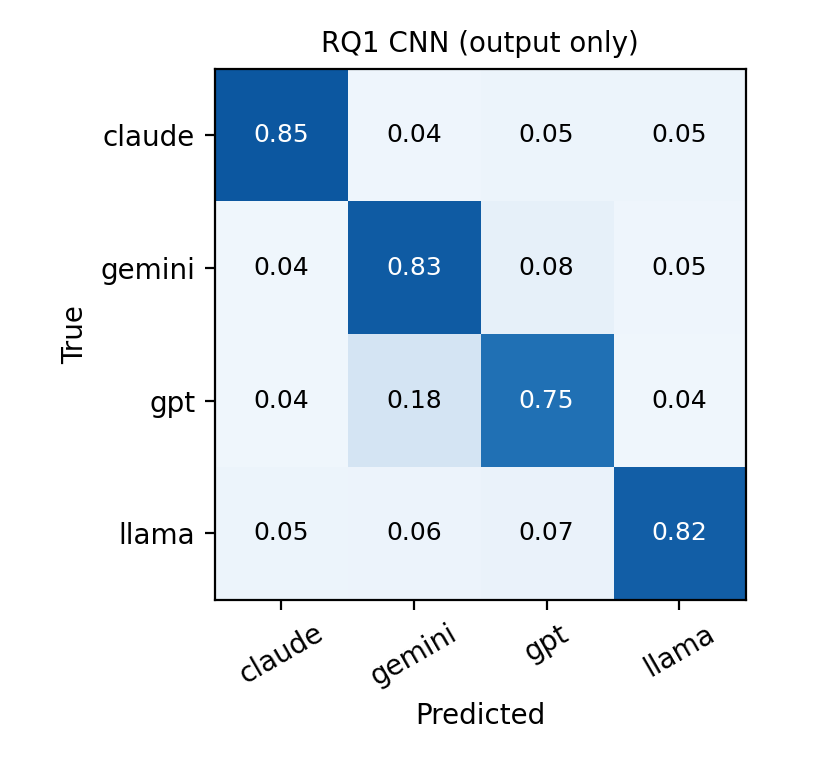

results/figs/rq1_cm_lstm.png


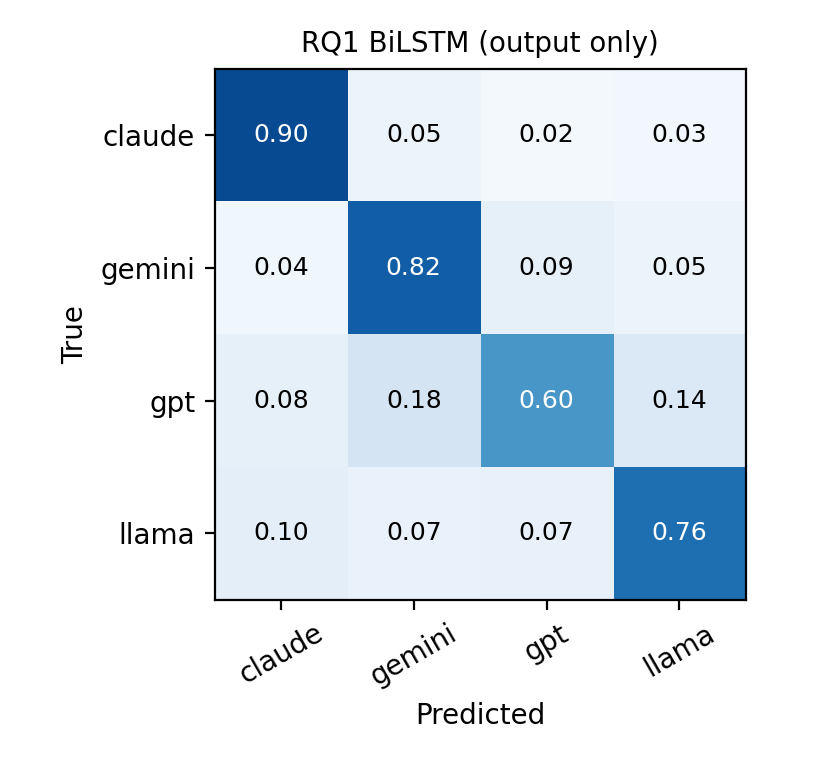

results/figs/rq2_modes.png


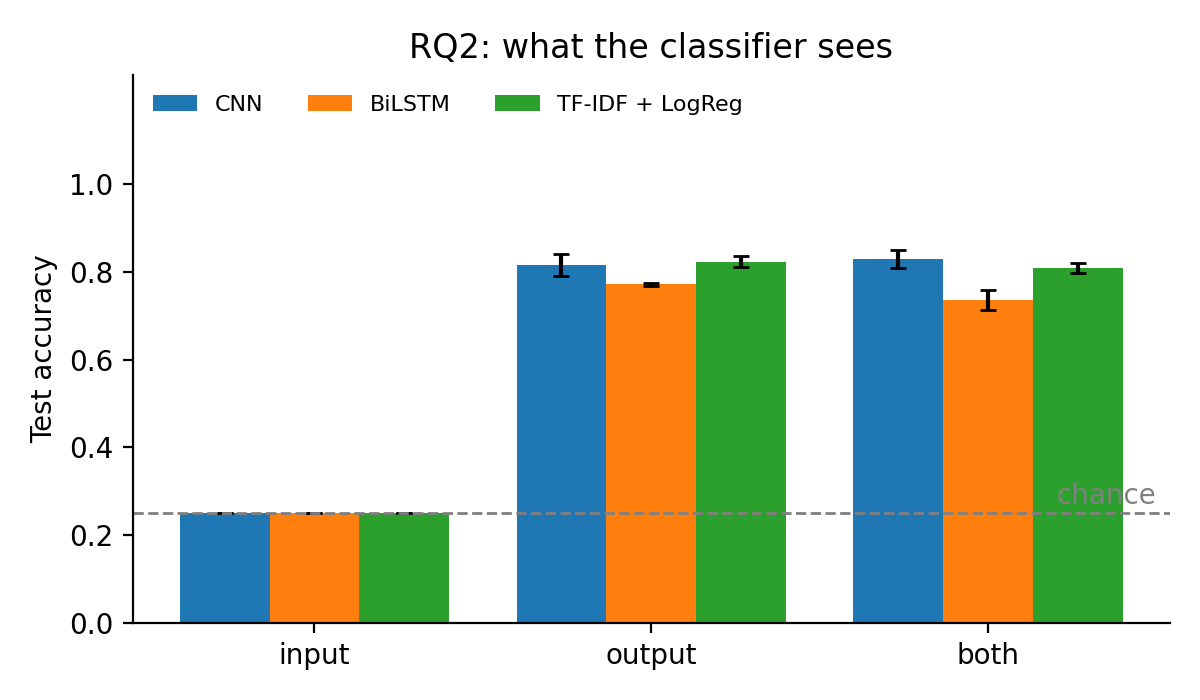

results/figs/rq3_cm_cnn_technical.png


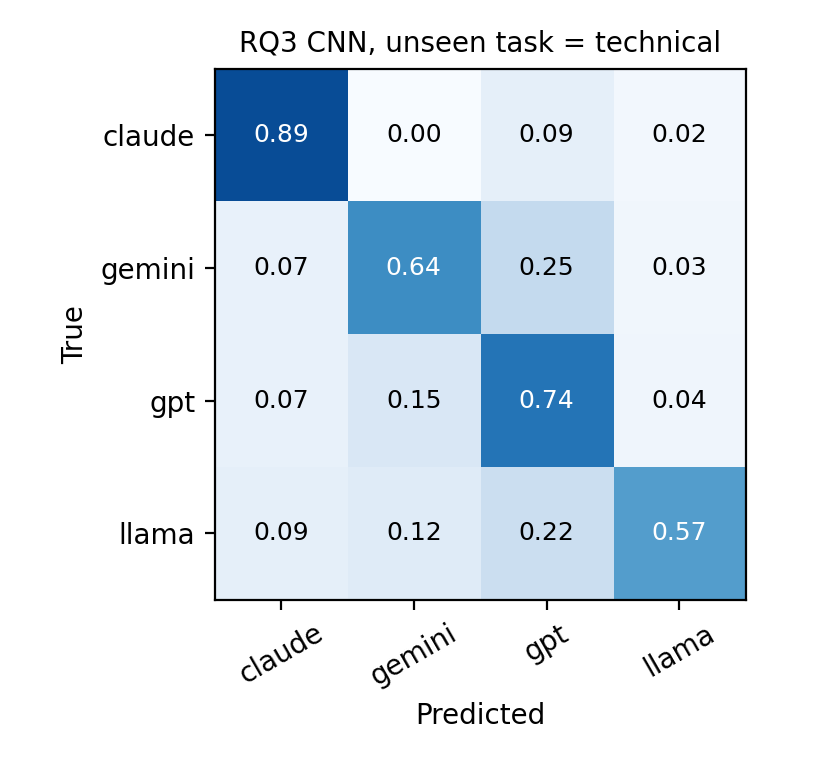

results/figs/rq3_cm_cnn_writing.png


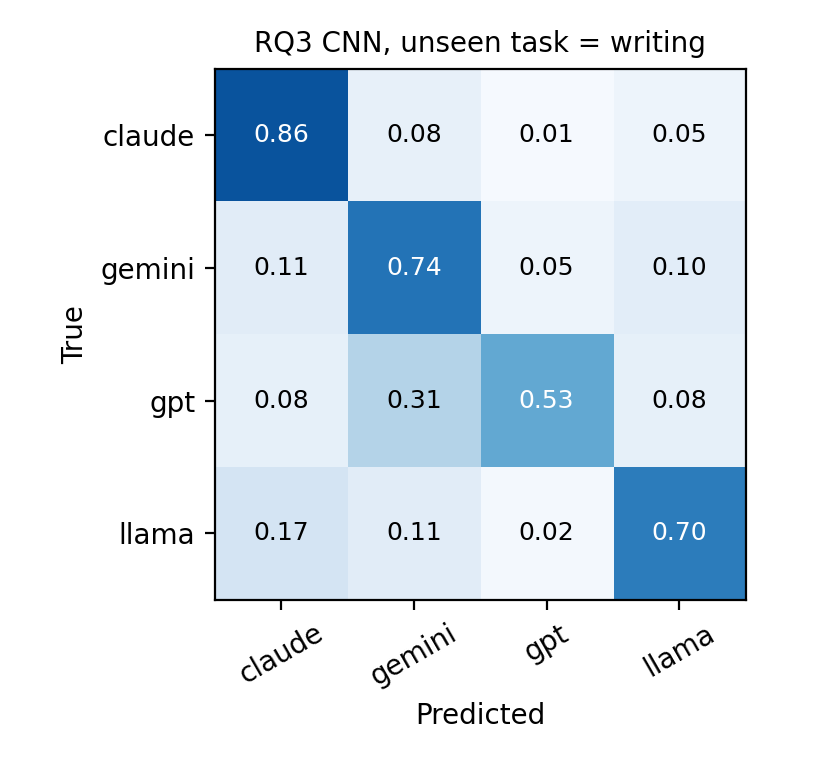

results/figs/rq3_cross_task.png


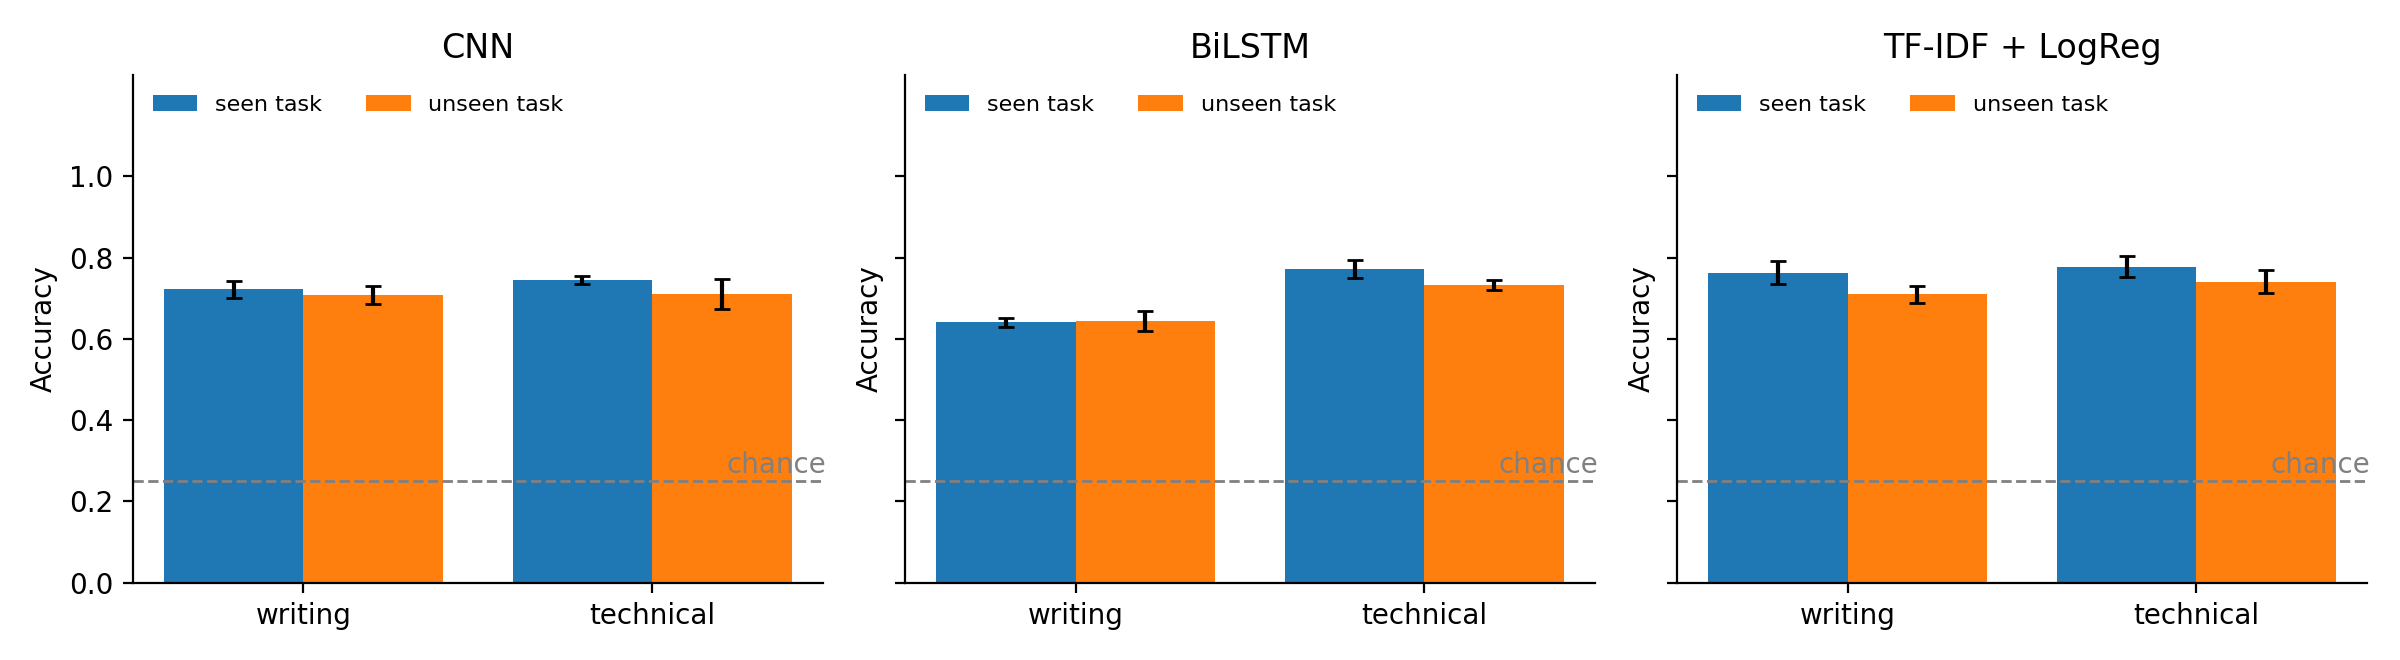

results/figs/rq4_ablations.png


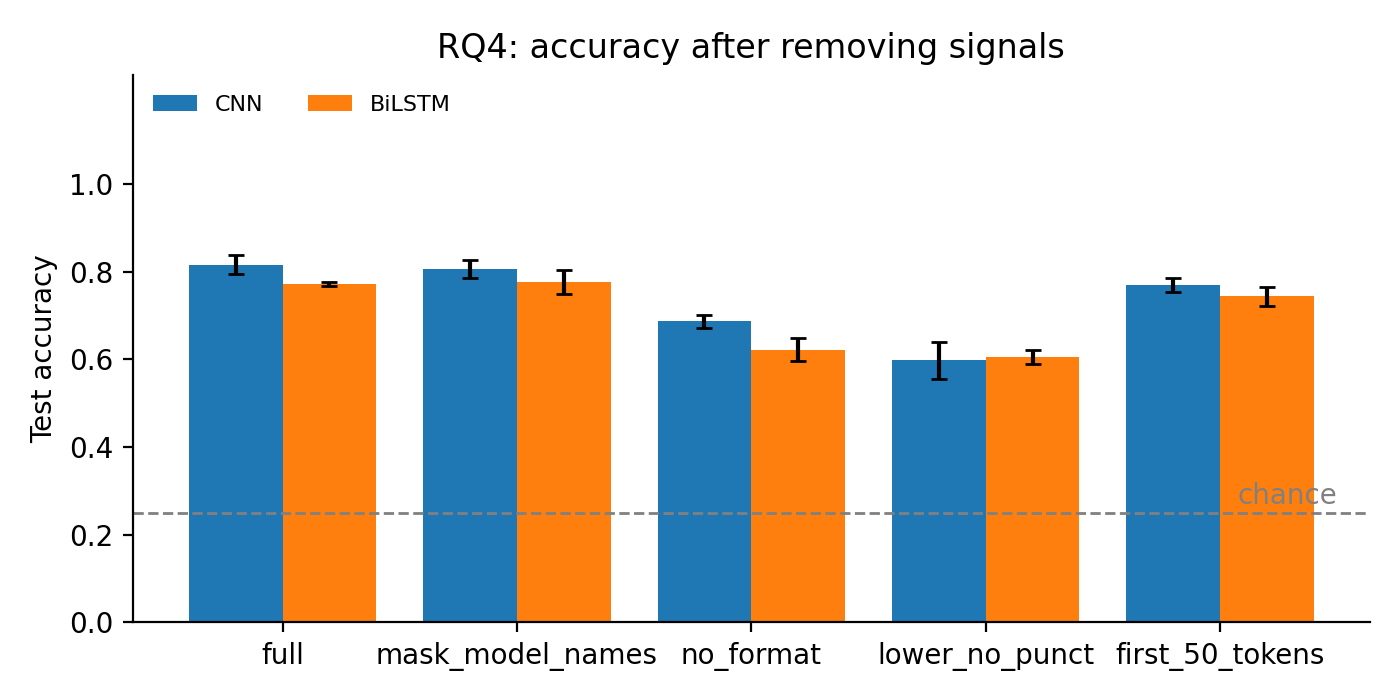

results/figs/rq4_style_stats.png


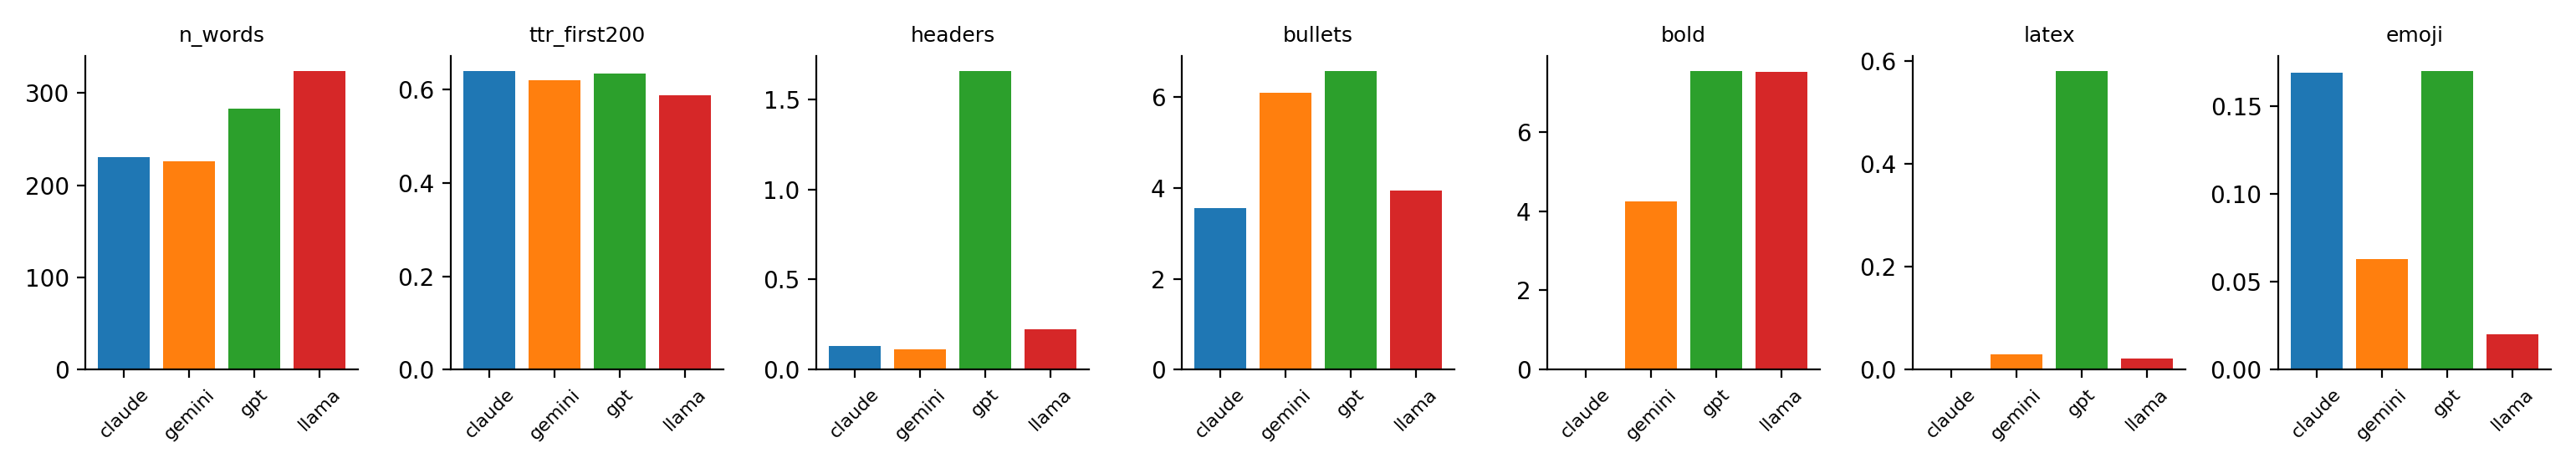

results/figs/training_curves.png


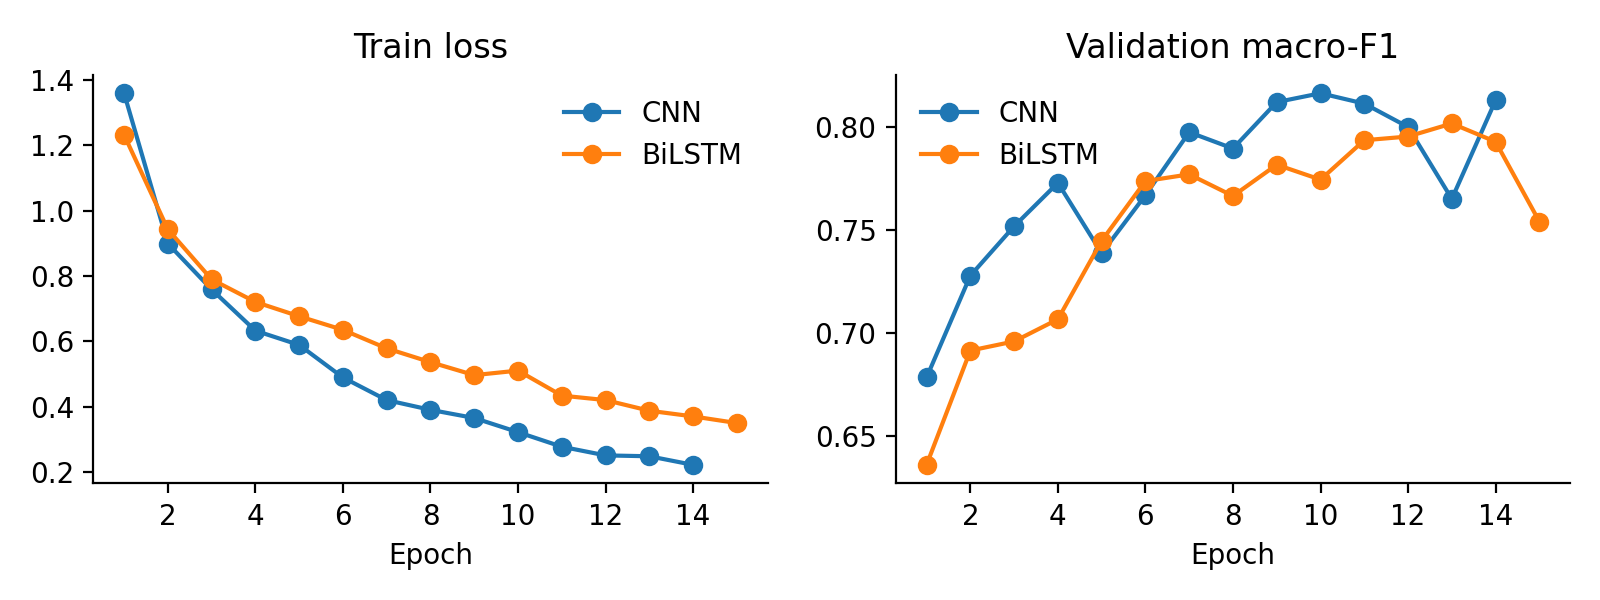

In [ ]:
!python report_figs.py
from IPython.display import Image, Markdown, display
import glob
display(Markdown(open('results/tables.md').read()))
for f in sorted(glob.glob('results/figs/*.png')):
    print(f); display(Image(f, width=650))

## 7. Download everything (for GitHub)

In [ ]:
!zip -qr /content/llm-fingerprint.zip . -x '*.ipynb_checkpoints*'
from google.colab import files
files.download('/content/llm-fingerprint.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>